# WildGuard-Fauna · Notebook único del proyecto

Este cuaderno reemplaza a todos los anteriores. Ejecútalo de arriba a abajo.

## Antes de ejecutar
1. Coloca el dataset en `./dataset_animals10/` con una carpeta por clase.
2. Si tienes el modelo CNN, colócalo en `./models/wildguard_cnn_final.keras`.
3. Si no existe, la sección 5 usa una CNN simulada para que SARSA y el GIF corran; la evaluación real necesita el modelo.

## Estructura
- Sección 0: configuración y semillas.
- Sección 1: EDA, split 70/15/15.
- Sección 2: features color + LBP + HOG, guardadas como `.npy`.
- Sección 3: supervisado con GridSearchCV y métricas.
- Sección 4: no supervisado y métricas (Betzie) usando `X_test.npy` reales.
- Sección 5: CNN.
- Sección 6: MDP y entorno Gymnasium.
- Sección 7: SARSA, baseline, evaluación y GIF.
- Sección 8: resumen y tabla de tareas.

In [1]:
%pip install scikit-image scikit-learn pandas numpy matplotlib seaborn opencv-python kagglehub tensorflow gymnasium imageio joblib pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# =========================================================
# 0. CONFIGURACIÓN, SEMILLAS E IMPORTS
# =========================================================
import os
import random
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from skimage.feature import local_binary_pattern, hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, silhouette_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA
import joblib
import gymnasium as gym
from gymnasium import spaces

# --- DESCARGA AUTOMÁTICA DEL DATASET ---
import kagglehub
print("Descargando/verificando dataset...")
path_descarga = kagglehub.dataset_download("alessiocorrado99/animals10")
DATASET_DIR = Path(path_descarga) / "raw-img"
if not DATASET_DIR.exists():
    DATASET_DIR = Path(path_descarga)
# ---------------------------------------

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import tensorflow as tf
        tf.random.set_seed(seed)
    except Exception:
        pass

seed_everything(SEED)

# --- CREACIÓN DE CARPETAS SEGURA ---
# Esto asegura que se creen en la carpeta donde está el notebook
PROCESSED_DIR = Path("./processed_data").resolve()
MODELS_DIR = Path("./models").resolve()
RESULTS_DIR = Path("./resultados").resolve()

for d in [PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    d.mkdir(exist_ok=True, parents=True)
# -----------------------------------

CLASSES = [
    "cane", "cavallo", "elefante", "farfalla", "gallina",
    "gatto", "mucca", "pecora", "ragno", "scoiattolo"
]

if DATASET_DIR.exists():
    encontradas = sorted([p.name for p in DATASET_DIR.iterdir() if p.is_dir()])
    if encontradas:
        CLASSES = encontradas

print("Semilla:", SEED)
print("Dataset en:", DATASET_DIR)
print("Carpeta de resultados:", RESULTS_DIR)
print("Clases:", CLASSES)

c:\Users\Jasciel\anaconda3\envs\WildGuard-Fauna\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Descargando/verificando dataset...
Semilla: 42
Dataset en: C:\Users\Jasciel\.cache\kagglehub\datasets\alessiocorrado99\animals10\versions\2\raw-img
Carpeta de resultados: C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados
Clases: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']


        clase     n
0        cane  4863
1     cavallo  2623
2    elefante  1446
3    farfalla  2112
4     gallina  3098
5       gatto  1668
6       mucca  1866
7      pecora  1820
8       ragno  4821
9  scoiattolo  1862
Total: 26179


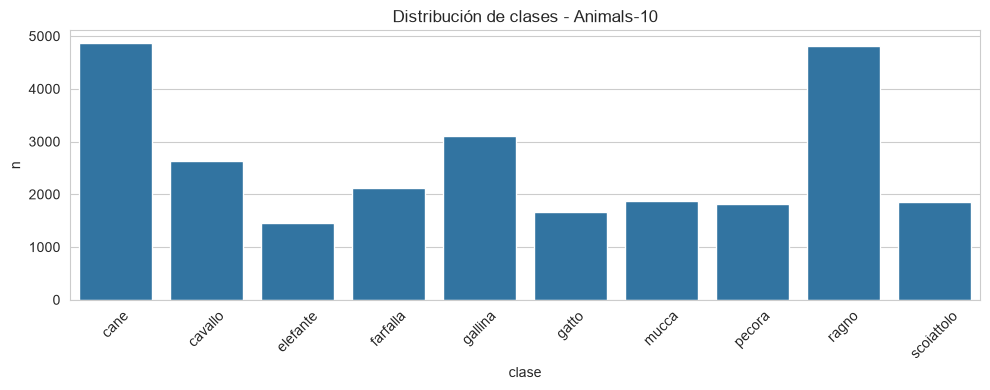

Tamaños (min, max, media): [150 150] [640 640] [332.9 406.2]


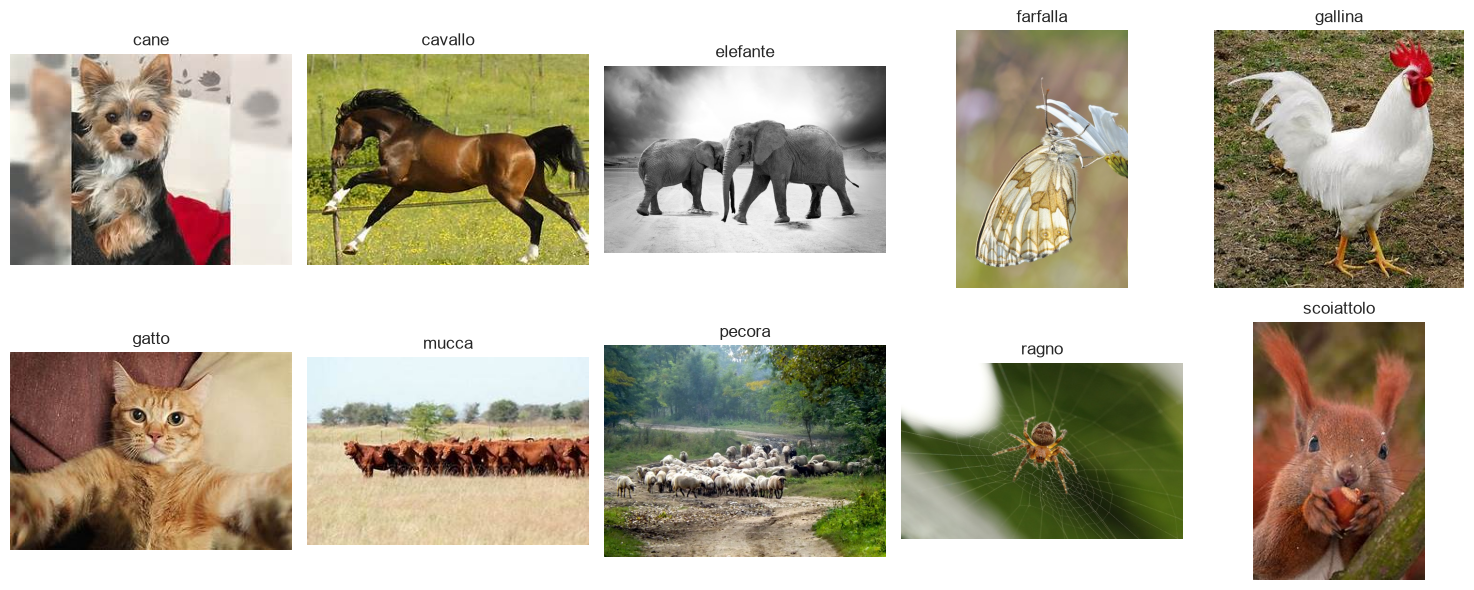

In [3]:
# =========================================================
# 1.1 EDA: distribución, ejemplos, tamaños, dañados
# =========================================================
def contar_clases(dataset_dir):
    filas = []
    for cls in CLASSES:
        d = dataset_dir / cls
        if not d.exists(): continue
        archivos = [p for p in d.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
        filas.append((cls, len(archivos)))
    return pd.DataFrame(filas, columns=["clase", "n"])

if DATASET_DIR.exists():
    df_counts = contar_clases(DATASET_DIR)
    print(df_counts)
    print("Total:", int(df_counts["n"].sum()))

    plt.figure(figsize=(10, 4))
    sns.barplot(data=df_counts, x="clase", y="n")
    plt.xticks(rotation=45)
    plt.title("Distribución de clases - Animals-10")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "eda_distribucion_clases.png", dpi=150)
    plt.show()

    sample_paths = []
    sizes = []
    for cls in df_counts["clase"]:
        d = DATASET_DIR / cls
        archivos = [p for p in d.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
        for p in archivos[:5]:
            img = cv2.imread(str(p))
            if img is not None: sizes.append(img.shape[:2])
        if archivos: sample_paths.append((cls, archivos[0]))

    if sizes:
        sizes = np.array(sizes)
        print("Tamaños (min, max, media):", sizes.min(axis=0), sizes.max(axis=0), sizes.mean(axis=0))

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for ax, (cls, p) in zip(axes.ravel(), sample_paths[:10]):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(cls)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "eda_ejemplos.png", dpi=150)
    plt.show()

In [4]:
# =========================================================
# 1.2 Split 70/15/15 estratificado
# =========================================================
def crear_splits():
    train_csv = PROCESSED_DIR / "train_split.csv"
    val_csv = PROCESSED_DIR / "val_split.csv"
    test_csv = PROCESSED_DIR / "test_split.csv"

    if train_csv.exists() and val_csv.exists() and test_csv.exists():
        print("CSV de split ya existen. Cargando.")
        return pd.read_csv(train_csv), pd.read_csv(val_csv), pd.read_csv(test_csv)

    paths, labels, corruptos = [], [], []
    for idx, cls in enumerate(CLASSES):
        d = DATASET_DIR / cls
        if not d.exists(): continue
        for p in d.iterdir():
            if p.suffix.lower() not in [".jpg", ".jpeg", ".png"]: continue
            img = cv2.imread(str(p))
            if img is None: corruptos.append(str(p))
            else:
                paths.append(str(p))
                labels.append(idx)

    print("Imágenes válidas:", len(paths), "| Archivos dañados:", len(corruptos))

    Xtr, Xtmp, ytr, ytmp = train_test_split(paths, labels, test_size=0.30, random_state=SEED, stratify=labels)
    Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.50, random_state=SEED, stratify=ytmp)

    df_tr = pd.DataFrame({"path": Xtr, "label": ytr})
    df_va = pd.DataFrame({"path": Xva, "label": yva})
    df_te = pd.DataFrame({"path": Xte, "label": yte})

    df_tr.to_csv(train_csv, index=False)
    df_va.to_csv(val_csv, index=False)
    df_te.to_csv(test_csv, index=False)
    return df_tr, df_va, df_te

df_train, df_val, df_test = crear_splits()
print("Train:", len(df_train), "| Val:", len(df_val), "| Test:", len(df_test))

CSV de split ya existen. Cargando.
Train: 18325 | Val: 3927 | Test: 3927


## 2. Extracción de características
Se calculan histogramas de color HSV, LBP y HOG a 128×128. El resultado se guarda en `processed_data/` como archivos `.npy`.

In [6]:
# =========================================================
# 2.1 Funciones de extracción
# =========================================================
def extract_color_histogram(image, bins=(8, 8, 8)):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

def extract_lbp_features(image_gray, radius=1, n_points=8):
    lbp = local_binary_pattern(image_gray, n_points, radius, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist

def extract_hog_features(image_gray):
    resized = cv2.resize(image_gray, (64, 64))
    return hog(resized, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys", visualize=False)

def extract_all_features(image_path):
    image = cv2.imread(str(image_path))
    if image is None: raise ValueError(f"No se pudo leer: {image_path}")
    image = cv2.resize(image, (128, 128))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return np.hstack([extract_color_histogram(image), extract_lbp_features(gray), extract_hog_features(gray)]).astype("float32")

In [7]:
# =========================================================
# 2.2 Extraer features y guardar en .npy
# =========================================================
def extraer_features(df, nombre):
    out_x = PROCESSED_DIR / f"X_{nombre}.npy"
    out_y = PROCESSED_DIR / f"y_{nombre}.npy"

    if out_x.exists() and out_y.exists():
        X = np.load(out_x)
        y = np.load(out_y)
        print(f"[cache] {nombre}: {X.shape}")
        return X, y

    X, y = [], df["label"].values
    for i, p in enumerate(df["path"].values):
        X.append(extract_all_features(p))
        if (i + 1) % 2000 == 0: print(f"  {nombre}: {i + 1}/{len(df)}")

    X = np.vstack(X)
    np.save(out_x, X)
    np.save(out_y, y)
    print(f"Guardado {out_x.name} con forma {X.shape}")
    return X, y

X_train, y_train = extraer_features(df_train, "train")
X_val, y_val = extraer_features(df_val, "val")
X_test, y_test = extraer_features(df_test, "test")
print("Listo.")

[cache] train: (18325, 2286)
[cache] val: (3927, 2286)
[cache] test: (3927, 2286)
Listo.


## 3. Aprendizaje supervisado
Tres modelos con `GridSearchCV`: LogisticRegression, RandomForest y SVM.

In [8]:
# =========================================================
# 3.1 Entrenamiento
# =========================================================
param_grids = {
    'LogisticRegression': {'model': LogisticRegression(max_iter=1000, random_state=SEED), 'params': {'C': [0.1, 1.0, 10.0]}},
    'RandomForest': {'model': RandomForestClassifier(random_state=SEED), 'params': {'n_estimators': [50, 100], 'max_depth': [10, 20, None]}}
    #'SVM': {'model': SVC(random_state=SEED), 'params': {'C': [0.1, 1.0, 10.0], 'kernel': ['rbf', 'linear']}},
}

best_models = {}
for model_name, config in param_grids.items():
    pkl_path = MODELS_DIR / f"{model_name}_best.pkl"
    if pkl_path.exists():
        best_models[model_name] = joblib.load(pkl_path)
        print(f"[cache] {model_name} cargado.")
        continue

    print(f"\nEntrenando {model_name}...")
    grid = GridSearchCV(estimator=config['model'], param_grid=config['params'], cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
    grid.fit(X_train, y_train)
    best_models[model_name] = grid.best_estimator_
    print("Mejores hiperparámetros:", grid.best_params_)
    joblib.dump(grid.best_estimator_, pkl_path)


Entrenando LogisticRegression...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Mejores hiperparámetros: {'C': 0.1}
[cache] RandomForest cargado.


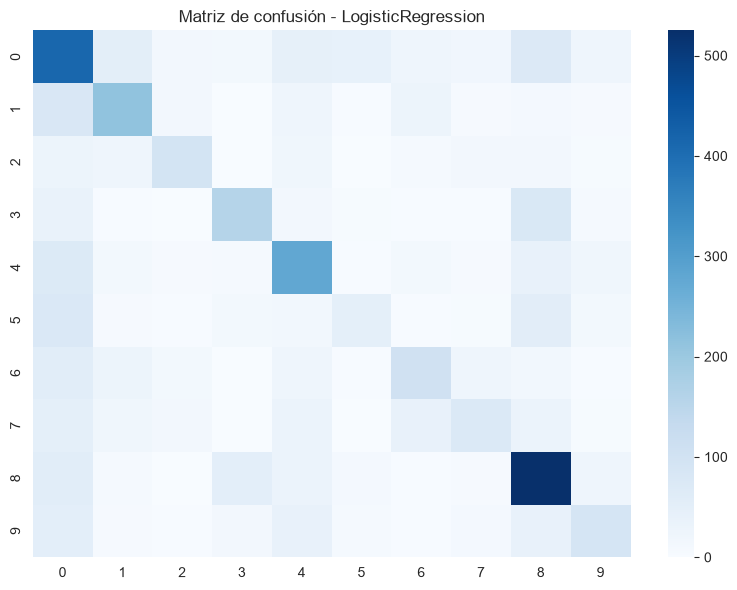

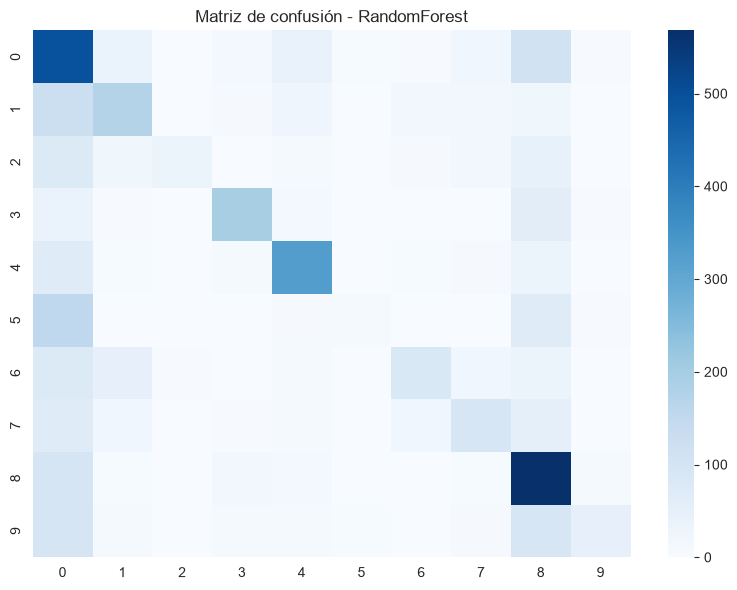

               modelo  accuracy  precision_macro  recall_macro  f1_macro
0  LogisticRegression  0.511077         0.495148      0.455590  0.467066
1        RandomForest  0.516425         0.577161      0.423181  0.436532
Guardado test_features_and_preds.npz


In [9]:
# =========================================================
# 3.2 Predicciones sobre test y npz
# =========================================================
predicciones = {}
metricas = []

for nombre, modelo in best_models.items():
    y_pred = modelo.predict(X_test)
    predicciones[nombre] = y_pred
    metricas.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=False, cmap="Blues")
    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"matriz_confusion_{nombre}.png", dpi=150)
    plt.show()

df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(RESULTS_DIR / "metricas_supervisado.csv", index=False)
print(df_metricas)

np.savez(PROCESSED_DIR / "test_features_and_preds.npz", X_test=X_test, y_test=y_test, **predicciones)
print("Guardado test_features_and_preds.npz")

## 4. Aprendizaje no supervisado y métricas (Betzie)
Carga `X_test.npy` y `y_test.npy` reales. K-Means (k=10) y DBSCAN sobre PCA-50.

In [10]:
# =========================================================
# 4.1 K-Means y DBSCAN, silueta, pureza, ARI
# =========================================================
def pureza(y_true, y_pred):
    total = 0
    for c in np.unique(y_pred):
        if c == -1: continue
        mask = y_pred == c
        if mask.sum() == 0: continue
        _, counts = np.unique(y_true[mask], return_counts=True)
        total += counts.max()
    return total / len(y_true)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_test)
pca = PCA(n_components=50, random_state=SEED)
X_cluster = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=10, random_state=SEED, n_init=10)
y_kmeans = kmeans.fit_predict(X_cluster)
sil_kmeans = silhouette_score(X_cluster, y_kmeans, sample_size=min(2000, len(X_cluster)), random_state=SEED)

mejor_dbscan = None
mejor_score = -1
for eps in [1.5, 2.0, 2.5, 3.0, 4.0]:
    db = DBSCAN(eps=eps, min_samples=10)
    labels = db.fit_predict(X_cluster)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters > mejor_score:
        mejor_score = n_clusters
        mejor_dbscan = (eps, labels)

eps_sel, y_dbscan = mejor_dbscan
mask_db = y_dbscan != -1
sil_dbscan = silhouette_score(X_cluster[mask_db], y_dbscan[mask_db], sample_size=min(2000, int(mask_db.sum())), random_state=SEED) if mask_db.sum() > 1 else float("nan")

print("K-Means | Silueta:", round(float(sil_kmeans), 4), "| Pureza:", round(float(pureza(y_test, y_kmeans)), 4), "| ARI:", round(float(adjusted_rand_score(y_test, y_kmeans)), 4))
print("DBSCAN | Silueta:", sil_dbscan, "| Pureza:", round(float(pureza(y_test, y_dbscan)), 4), "| ARI:", round(float(adjusted_rand_score(y_test, y_dbscan)), 4))

pd.DataFrame([
    {"metodo": "KMeans_k10", "silueta": float(sil_kmeans), "pureza": float(pureza(y_test, y_kmeans)), "ARI": float(adjusted_rand_score(y_test, y_kmeans))},
    {"metodo": "DBSCAN", "silueta": float(sil_dbscan), "pureza": float(pureza(y_test, y_dbscan)), "ARI": float(adjusted_rand_score(y_test, y_dbscan))},
]).to_csv(RESULTS_DIR / "metricas_no_supervisado.csv", index=False)

K-Means | Silueta: 0.0149 | Pureza: 0.2793 | ARI: 0.0402
DBSCAN | Silueta: nan | Pureza: 0.0 | ARI: 0.0


## 5. CNN y clasificador

Carga el modelo real si existe. Si no existe, usa una CNN simulada para que el entorno de refuerzo pueda ejecutarse. La evaluación final requiere el modelo real.

In [11]:
# =========================================================
# 5.1 Clasificador CNN
# =========================================================
class WildGuardCNN:
    def __init__(self, model_path=MODELS_DIR / "wildguard_cnn_final.keras", metadata_path=MODELS_DIR / "model_metadata.json", dataset_dir=DATASET_DIR, simulated=False):
        self.model = None
        self.simulated = simulated
        self.img_size = (128, 128)
        self.class_names = CLASSES.copy()
        self.dataset_dir = Path(dataset_dir)
        self._cache = {}

        if metadata_path.exists():
            with open(metadata_path, "r", encoding="utf-8") as f:
                meta = json.load(f)
            self.class_names = meta.get("class_names", meta.get("classes", self.class_names))
            if "input_shape" in meta:
                self.img_size = (meta["input_shape"][1], meta["input_shape"][0])

        if Path(model_path).exists() and not simulated:
            import tensorflow as tf
            self.model = tf.keras.models.load_model(model_path)
            _, h, w, _ = self.model.input_shape
            self.img_size = (w, h)
        else:
            print("Aviso: modelo CNN no encontrado. Se usará CNN simulada.")
            self.simulated = True
        self.imagenes_por_clase = self._indexar_imagenes()

    def _indexar_imagenes(self):
        indice = {}
        for cls in self.class_names:
            d = self.dataset_dir / cls
            if d.exists():
                archivos = [str(p) for p in d.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
                if archivos: indice[cls] = archivos
        return indice

    def predecir_imagen(self, ruta_imagen):
        ruta_imagen = str(ruta_imagen)
        if ruta_imagen in self._cache: return self._cache[ruta_imagen]

        if self.simulated:
            clase_real = Path(ruta_imagen).parent.name
            acierto = np.random.rand() < 0.95
            especie = clase_real if acierto else np.random.choice(self.class_names)
            confianza = float(np.random.uniform(0.70, 1.0) if acierto else np.random.uniform(0.30, 0.70))
            self._cache[ruta_imagen] = (especie, confianza)
            return especie, confianza

        img = cv2.imread(ruta_imagen)
        if img is None: raise FileNotFoundError(f"No se pudo leer: {ruta_imagen}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, self.img_size)
        arr = img.astype("float32") / 255.0
        arr = np.expand_dims(arr, axis=0)

        preds = self.model.predict(arr, verbose=0)[0]
        idx = int(np.argmax(preds))
        especie = self.class_names[idx]
        confianza = float(preds[idx])

        self._cache[ruta_imagen] = (especie, confianza)
        return especie, confianza

    def tomar_foto_aleatoria(self, clase_real=None):
        if not self.imagenes_por_clase: raise RuntimeError("No hay imágenes indexadas para la CNN.")
        if clase_real is None or clase_real not in self.imagenes_por_clase:
            clase_real = np.random.choice(list(self.imagenes_por_clase.keys()))

        ruta = np.random.choice(self.imagenes_por_clase[clase_real])
        especie_pred, confianza = self.predecir_imagen(ruta)
        return {"clase_real": clase_real, "especie_predicha": especie_pred, "confianza": confianza, "acierto": especie_pred == clase_real, "ruta": ruta}

cnn = WildGuardCNN()
print("CNN simulada:", cnn.simulated)
if cnn.imagenes_por_clase:
    prueba = cnn.tomar_foto_aleatoria()
    print("Prueba:", prueba["clase_real"], "->", prueba["especie_predicha"], f"({prueba['confianza']:.1%})")

CNN simulada: False
Prueba: mucca -> mucca (98.9%)


## 5.2 Evaluación de la CNN: Imágenes Recortadas y Análisis de Errores (E2)
Se evalúa el impacto del fondo recortando el centro de las imágenes y se genera la matriz de confusión.

Imágenes cargadas: 3927 de 3927
123/123 ━━━━━━━━━━━━━━━━━━━━ 43s 324ms/step


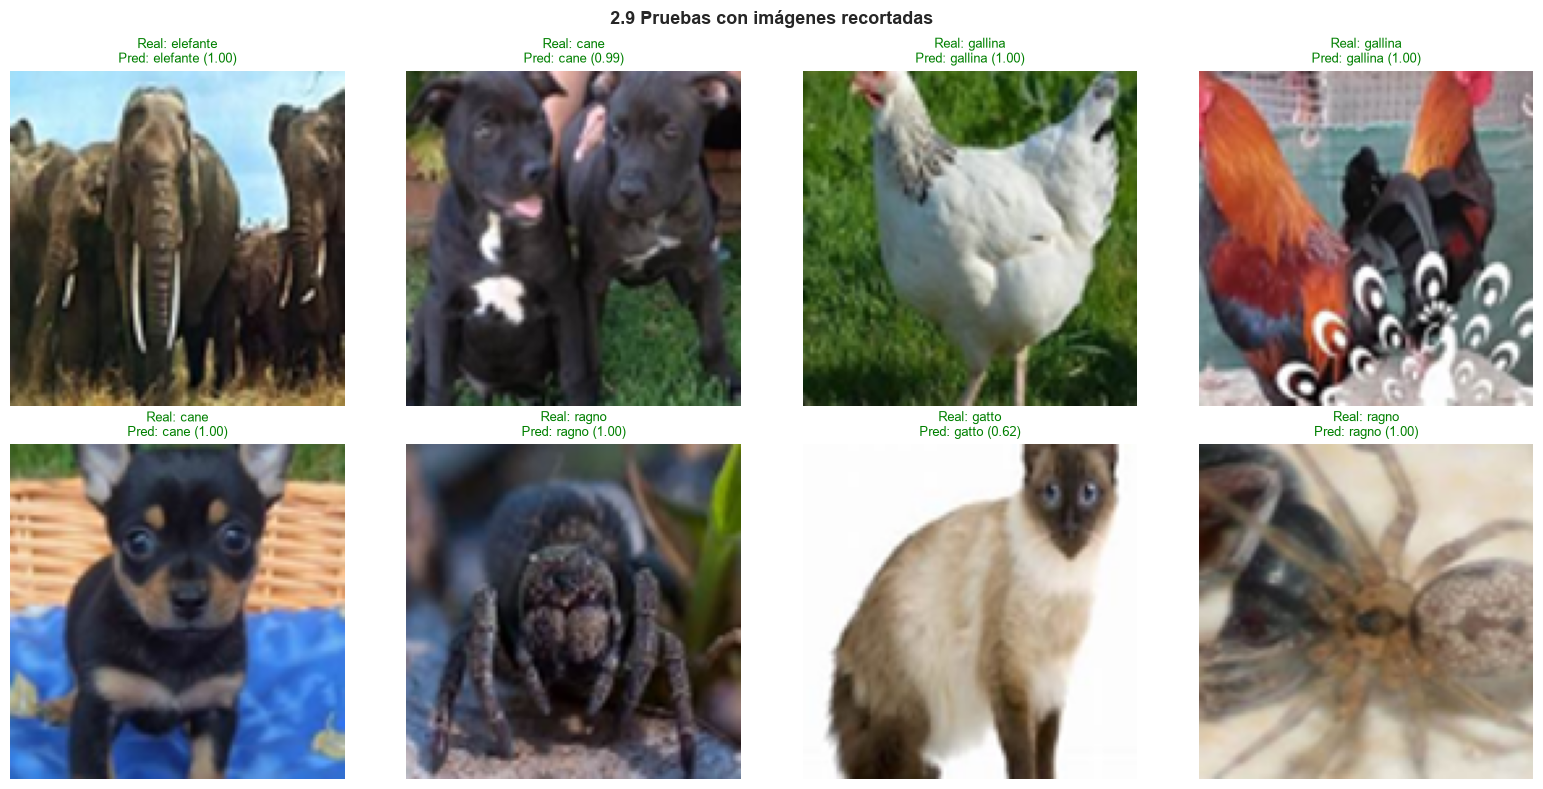


=== Reporte de clasificación ===
              precision    recall  f1-score   support

        cane     0.9383    0.9575    0.9478       730
     cavallo     0.9120    0.9491    0.9302       393
    elefante     0.9505    0.9724    0.9613       217
    farfalla     0.9655    0.9716    0.9686       317
     gallina     0.9778    0.9484    0.9629       465
       gatto     0.9593    0.9440    0.9516       250
       mucca     0.9065    0.9000    0.9032       280
      pecora     0.9280    0.8974    0.9125       273
       ragno     0.9873    0.9696    0.9784       723
  scoiattolo     0.9470    0.9606    0.9537       279

    accuracy                         0.9509      3927
   macro avg     0.9472    0.9471    0.9470      3927
weighted avg     0.9512    0.9509    0.9509      3927



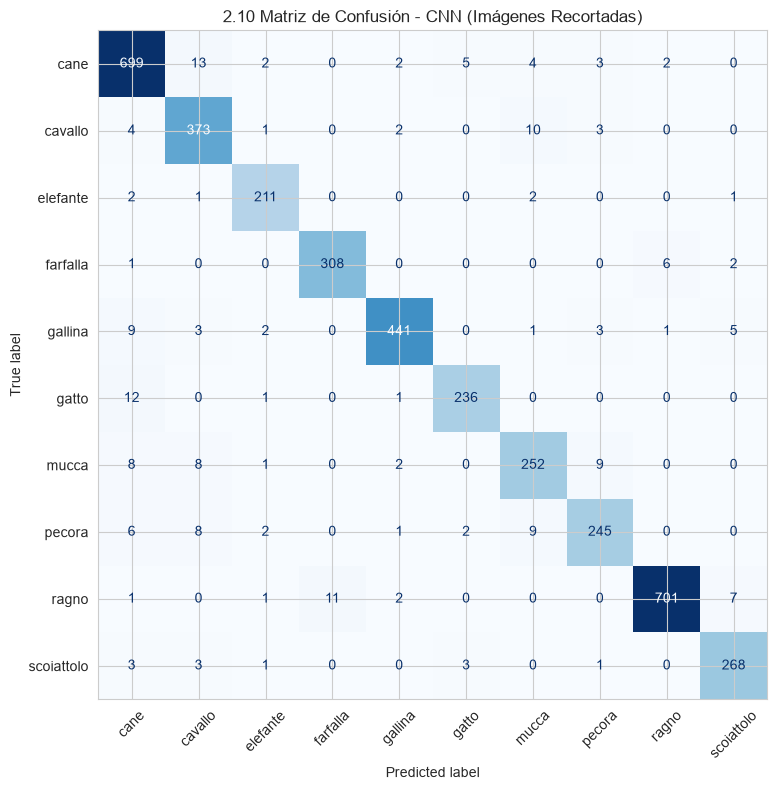

In [12]:
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

modelo_cnn = cnn.model if cnn.model is not None else None
class_names = cnn.class_names
img_h, img_w = cnn.img_size[1], cnn.img_size[0]

def resolver_ruta(p):
    if pd.isna(p): return None
    p_str = str(p)
    if os.path.exists(p_str): return p_str
    partes = p_str.replace("\\", "/").split("/")
    if "raw-img" in partes:
        idx = partes.index("raw-img")
        subruta = os.path.join(*partes[idx:])
        if os.path.exists(subruta): return subruta
    return None

df_test = pd.read_csv("processed_data/test_split.csv")
imagenes, etiquetas = [], []
for _, row in df_test.iterrows():
    ruta_ok = resolver_ruta(row["path"])
    if ruta_ok is not None:
        try:
            with Image.open(ruta_ok) as im:
                im_rgb = im.convert("RGB").resize((img_w, img_h))
                imagenes.append(np.asarray(im_rgb, dtype=np.float32) / 255.0)
                etiquetas.append(int(row["label"]))
        except Exception:
            pass

X_test_img = np.array(imagenes, dtype=np.float32)
y_true = np.array(etiquetas, dtype=np.int64)
print(f"Imágenes cargadas: {len(X_test_img)} de {len(df_test)}")

def hacer_recorte_central(img_norm, frac=0.7):
    h, w, _ = img_norm.shape
    nh, nw = int(h * frac), int(w * frac)
    top, left = (h - nh) // 2, (w - nw) // 2
    crop = img_norm[top:top+nh, left:left+nw]
    crop_uint8 = np.clip(crop * 255.0, 0, 255).astype(np.uint8)
    resized = Image.fromarray(crop_uint8).resize((w, h))
    return np.asarray(resized, dtype=np.float32) / 255.0

crops_test = np.array([hacer_recorte_central(img, frac=0.7) for img in X_test_img], dtype=np.float32)
y_probs = modelo_cnn.predict(crops_test, batch_size=32, verbose=1)
y_pred = np.argmax(y_probs, axis=1)
confidences = np.max(y_probs, axis=1)

def visualizar_recortes(crops, y_true, y_pred, confidences, class_names, n_samples=8):
    n_samples = min(n_samples, len(crops))
    cols = 4
    rows = int(np.ceil(n_samples / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)
    for i in range(len(axes)):
        ax = axes[i]
        if i < n_samples:
            img = crops[i]
            img_show = np.clip(img, 0, 1) if img.max() <= 1.0 else np.clip(img, 0, 255).astype(np.uint8)
            ax.imshow(img_show)
            real_lbl = class_names[y_true[i]] if y_true is not None else "N/D"
            pred_lbl = class_names[y_pred[i]]
            ok = (y_true is not None) and (y_true[i] == y_pred[i])
            color = "green" if ok else "red"
            ax.set_title(f"Real: {real_lbl}\nPred: {pred_lbl} ({confidences[i]:.2f})", color=color, fontsize=9)
        ax.axis("off")
    plt.suptitle("2.9 Pruebas con imágenes recortadas", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

visualizar_recortes(crops_test, y_true, y_pred, confidences, class_names, n_samples=8)

print("\n=== Reporte de clasificación ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("2.10 Matriz de Confusión - CNN (Imágenes Recortadas)")
plt.tight_layout()
plt.show()

## 6. MDP y entorno Gymnasium

### Formulación del MDP
El entorno se modela como un MDP finito con descuento: $\mathcal{M} = (\mathcal{S}, \mathcal{A}, P, R, \gamma)$

El estado completo se define como: $s_t = (x_t, y_t, b_t, V_t, \ell_t)$ donde $(x_t, y_t)$ es la posición en el mapa 10×10, $b_t \in [0, 100]$ es la batería, $V_t$ es el conjunto de celdas fotografiadas y $\ell_t$ es la última especie detectada por la CNN.

Para SARSA se usa una abstracción discreta: $\tilde{s}_t = (x_t, y_t, \text{nivel}(b_t), \text{ya\_fotografiada}_t)$

**Acciones:** arriba, abajo, izquierda, derecha, tomar foto y recargar.
**Recompensas:** costo por paso $-1$; río $-2$; foto en base $-5$; foto duplicada $-2$; detección correcta conf $\ge 0.70$: $+15$; correcta baja conf: $+8$; incorrecta: $-3$; recarga útil: $+35$; recarga innecesaria: $-2$; recarga fuera: $-5$; batería agotada: $-100$.

**Algoritmo:** SARSA on-policy con actualización:
$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \left[ r_{t+1} + \gamma Q(s_{t+1}, a_{t+1}) - Q(s_t, a_t) \right]$

In [13]:
# =========================================================
# 6.1 Entorno Gymnasium WildGuard
# =========================================================
class WildGuardEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, usar_cnn=True, max_steps=200, clasificador=None):
        super().__init__()
        self.grid_size = 10
        self.max_steps = max_steps
        self.usar_cnn = usar_cnn
        self.action_space = spaces.Discrete(6)
        self.mapa = [
            ["F", "H", "F", "F", "F", "R", "R", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "R", "P", "P", "P"],
            ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"],
            ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "R", "R", "R", "P", "P", "P"],
            ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"],
            ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "R", "R", "R", "P", "H", "P"],
        ]
        self.fauna_por_zona = {"F": ["scoiattolo", "ragno", "farfalla", "gatto", "cane"], "P": ["cavallo", "mucca", "pecora", "gallina", "elefante"], "R": ["elefante", "cavallo", "farfalla", "cane"]}
        self.observation_space = spaces.Box(low=np.array([0, 0, 0, 0, 0], dtype=np.float32), high=np.array([9, 9, 100, 3, 10], dtype=np.float32), dtype=np.float32)

        if clasificador is not None: self.clasificador = clasificador
        else: self.clasificador = WildGuardCNN(simulated=not usar_cnn)
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.agent_pos = np.array([0, 1], dtype=int)
        self.battery = 100
        self.last_detected_class = 0
        self.steps = 0
        self.celdas_fotografiadas = set()
        return self._get_obs(), {}

    def step(self, action):
        self.steps += 1
        self.battery = max(0, self.battery - 2)
        if action == 0 and self.agent_pos[0] > 0: self.agent_pos[0] -= 1
        elif action == 1 and self.agent_pos[0] < self.grid_size - 1: self.agent_pos[0] += 1
        elif action == 2 and self.agent_pos[1] > 0: self.agent_pos[1] -= 1
        elif action == 3 and self.agent_pos[1] < self.grid_size - 1: self.agent_pos[1] += 1

        terreno = self.mapa[self.agent_pos[0]][self.agent_pos[1]]
        reward = -1
        info = {"terreno": terreno}
        if terreno == "R": reward -= 2

        if action == 4:
            pos = (int(self.agent_pos[0]), int(self.agent_pos[1]))
            if terreno == "H": reward -= 5; info["evento"] = "sin_fauna_en_base"
            elif pos in self.celdas_fotografiadas: reward -= 2; info["evento"] = "celda_ya_fotografiada"
            else:
                self.celdas_fotografiadas.add(pos)
                especie_real = str(self.np_random.choice(self.fauna_por_zona[terreno]))
                if self.usar_cnn and self.clasificador is not None:
                    foto = self.clasificador.tomar_foto_aleatoria(clase_real=especie_real)
                    self.last_detected_class = self.clasificador.class_names.index(foto["especie_predicha"])
                    if foto["acierto"] and foto["confianza"] >= 0.70: reward += 15
                    elif foto["acierto"]: reward += 8
                    else: reward -= 3
                    info.update(foto)
                else:
                    if self.clasificador is not None and especie_real in self.clasificador.class_names:
                        self.last_detected_class = self.clasificador.class_names.index(especie_real)
                    reward += 15

        elif action == 5:
            if terreno == "H":
                if self.battery <= 50: reward += 35
                else: reward -= 2
                self.battery = 100
                info["evento"] = "recarga_exitosa"
            else: reward -= 5; info["evento"] = "recarga_fallida"

        terminated = self.battery <= 0
        if terminated: reward -= 100; info["evento"] = "bateria_agotada"
        truncated = self.steps >= self.max_steps
        return self._get_obs(), reward, terminated, truncated, info

    def _get_obs(self):
        terreno = self.mapa[self.agent_pos[0]][self.agent_pos[1]]
        mapping = {"F": 0, "R": 1, "P": 2, "H": 3}
        return np.array([self.agent_pos[0], self.agent_pos[1], self.battery, mapping.get(terreno, 0), self.last_detected_class], dtype=np.float32)

env_prueba = WildGuardEnv(usar_cnn=False, max_steps=20)
obs, _ = env_prueba.reset(seed=SEED)
print("Observación inicial:", obs)

Aviso: modelo CNN no encontrado. Se usará CNN simulada.
Observación inicial: [  0.   1. 100.   3.   0.]


## 7. SARSA, baseline aleatorio, evaluación y GIF
Entrenamiento con 2 configuraciones. Evaluación con CNN real.

In [14]:
# =========================================================
# 7.1 Funciones SARSA y entrenamiento
# =========================================================
def obtener_estado(obs, env):
    x = int(obs[0]); y = int(obs[1]); bat = int(obs[2])
    nivel = 0 if bat <= 20 else 1 if bat <= 40 else 2 if bat <= 50 else 3 if bat <= 75 else 4
    ya_foto = 1 if (x, y) in env.celdas_fotografiadas else 0
    return (x, y, nivel, ya_foto)

def elegir_accion(Q, estado, epsilon, rng):
    if rng.random() < epsilon: return int(rng.integers(0, 6))
    valores = Q[estado]
    max_val = np.max(valores)
    mejores = np.flatnonzero(np.isclose(valores, max_val))
    return int(rng.choice(mejores))

def entrenar_sarsa(config, episodios=3000, seed=SEED):
    env = WildGuardEnv(usar_cnn=False, max_steps=200)
    rng = np.random.default_rng(seed)
    Q = np.zeros((10, 10, 5, 2, 6), dtype=np.float32)
    recompensas, fotos = [], []
    epsilon = config["epsilon_inicio"]

    for ep in range(episodios):
        obs, _ = env.reset(seed=seed + ep)
        estado = obtener_estado(obs, env)
        accion = elegir_accion(Q, estado, epsilon, rng)
        total = 0.0
        done = False
        while not done:
            obs2, reward, terminated, truncated, _ = env.step(accion)
            done = terminated or truncated
            estado2 = obtener_estado(obs2, env)
            accion2 = elegir_accion(Q, estado2, epsilon, rng)
            objetivo = reward if terminated else reward + config["gamma"] * Q[estado2][accion2]
            Q[estado][accion] += config["alpha"] * (objetivo - Q[estado][accion])
            estado = estado2; accion = accion2; total += reward
        recompensas.append(total)
        fotos.append(len(env.celdas_fotografiadas))
        epsilon = max(config["epsilon_min"], epsilon * config["epsilon_decay"])
    return Q, recompensas, fotos

def evaluar_politica(Q, usar_cnn=True, max_steps=100, episodios=10, seed=SEED):
    env = WildGuardEnv(usar_cnn=usar_cnn, max_steps=max_steps)
    rng = np.random.default_rng(seed)
    retornos, eventos, trayectorias, puntos_foto = [], {}, [], []
    for ep in range(episodios):
        obs, _ = env.reset(seed=seed + ep)
        estado = obtener_estado(obs, env)
        total = 0.0
        tray = [(int(obs[0]), int(obs[1]))]
        done = False
        while not done:
            accion = elegir_accion(Q, estado, epsilon=0.0, rng=rng)
            obs, reward, terminated, truncated, info = env.step(accion)
            done = terminated or truncated
            estado = obtener_estado(obs, env)
            total += reward
            tray.append((int(obs[0]), int(obs[1])))
            ev = info.get("evento")
            if ev: eventos[ev] = eventos.get(ev, 0) + 1
            if "especie_predicha" in info: puntos_foto.append((int(obs[0]), int(obs[1])))
        retornos.append(total)
        trayectorias.append(tray)
    return float(np.mean(retornos)), eventos, trayectorias, puntos_foto

def politica_aleatoria(episodios=100, max_steps=100, seed=SEED):
    env = WildGuardEnv(usar_cnn=False, max_steps=max_steps)
    rng = np.random.default_rng(seed)
    retornos = []
    for ep in range(episodios):
        obs, _ = env.reset(seed=seed + ep)
        total = 0.0
        done = False
        while not done:
            obs, reward, terminated, truncated, _ = env.step(int(rng.integers(0, 6)))
            done = terminated or truncated
            total += reward
        retornos.append(total)
    return float(np.mean(retornos)), float(np.std(retornos))

configA = {"alpha": 0.1, "gamma": 0.95, "epsilon_inicio": 1.0, "epsilon_min": 0.05, "epsilon_decay": 0.9994}
configB = {"alpha": 0.2, "gamma": 0.99, "epsilon_inicio": 1.0, "epsilon_min": 0.05, "epsilon_decay": 0.999}

print("Entrenando configuración A...")
QA, recompensasA, fotosA = entrenar_sarsa(configA, episodios=3000)
print("Entrenando configuración B...")
QB, recompensasB, fotosB = entrenar_sarsa(configB, episodios=3000)

np.save(MODELS_DIR / "q_table_sarsa_A.npy", QA)
np.save(MODELS_DIR / "q_table_sarsa_B.npy", QB)
print("Tablas Q guardadas.")

Entrenando configuración A...
Aviso: modelo CNN no encontrado. Se usará CNN simulada.
Entrenando configuración B...
Aviso: modelo CNN no encontrado. Se usará CNN simulada.
Tablas Q guardadas.


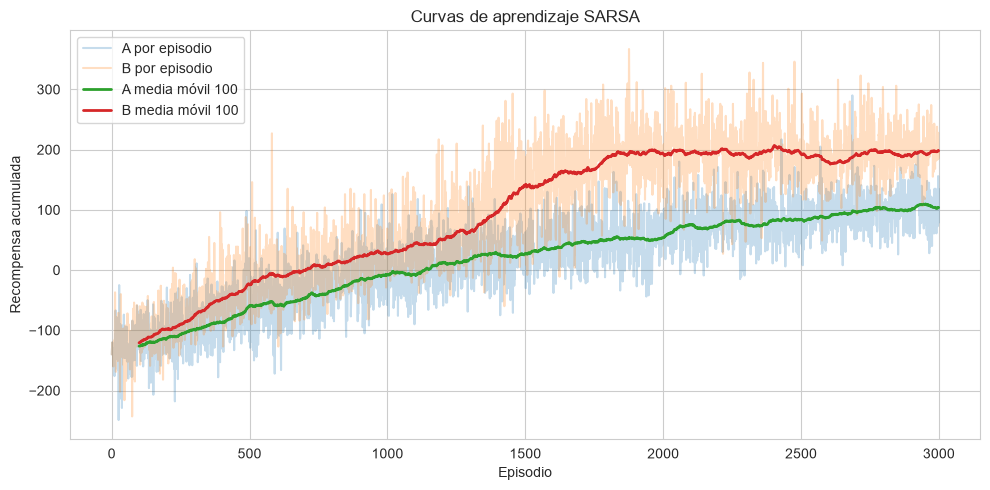

Aviso: modelo CNN no encontrado. Se usará CNN simulada.
Aleatoria: -129.89 +/- 34.77
SARSA A: 139.5 eventos: {'bateria_agotada': 10}
SARSA B: 148.6 eventos: {'recarga_exitosa': 30}


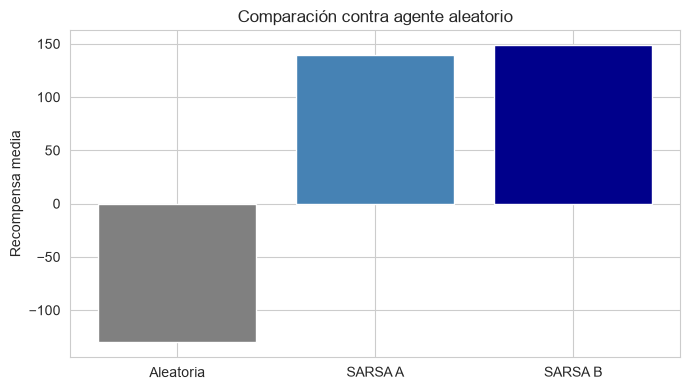

In [15]:
# =========================================================
# 7.2 Curvas, baseline y evaluación
# =========================================================
def media_movil(valores, ventana=100):
    if len(valores) < ventana: return np.array([])
    return np.convolve(valores, np.ones(ventana) / ventana, mode="valid")

plt.figure(figsize=(10, 5))
plt.plot(recompensasA, alpha=0.25, label="A por episodio")
plt.plot(recompensasB, alpha=0.25, label="B por episodio")
mA = media_movil(recompensasA)
mB = media_movil(recompensasB)
if len(mA): plt.plot(range(99, len(recompensasA)), mA, linewidth=2, label="A media móvil 100")
if len(mB): plt.plot(range(99, len(recompensasB)), mB, linewidth=2, label="B media móvil 100")
plt.title("Curvas de aprendizaje SARSA")
plt.xlabel("Episodio")
plt.ylabel("Recompensa acumulada")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "curvas_sarsa.png", dpi=150)
plt.show()

random_mean, random_std = politica_aleatoria(episodios=100, max_steps=100)
evalA, eventosA, trayA, ptsA = evaluar_politica(QA, usar_cnn=True, max_steps=100, episodios=10)
evalB, eventosB, trayB, ptsB = evaluar_politica(QB, usar_cnn=True, max_steps=100, episodios=10)

print("Aleatoria:", round(random_mean, 2), "+/-", round(random_std, 2))
print("SARSA A:", round(evalA, 2), "eventos:", eventosA)
print("SARSA B:", round(evalB, 2), "eventos:", eventosB)

plt.figure(figsize=(7, 4))
plt.bar(["Aleatoria", "SARSA A", "SARSA B"], [random_mean, evalA, evalB], color=["gray", "steelblue", "darkblue"])
plt.ylabel("Recompensa media")
plt.title("Comparación contra agente aleatorio")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparacion_aleatorio_sarsa.png", dpi=150)
plt.show()

pd.DataFrame([
    {"politica": "Aleatoria", "recompensa_media": random_mean, "std": random_std, "eventos": ""},
    {"politica": "SARSA A", "recompensa_media": evalA, "std": "", "eventos": json.dumps(eventosA, ensure_ascii=False)},
    {"politica": "SARSA B", "recompensa_media": evalB, "std": "", "eventos": json.dumps(eventosB, ensure_ascii=False)},
]).to_csv(RESULTS_DIR / "metricas_rl.csv", index=False)

In [17]:
# =========================================================
# 7.3 GIF de patrullaje
# =========================================================
import imageio.v2 as imageio

def crear_gif(trayectoria, puntos_foto, path_salida, max_frames=60):
    colores = {"F": [0.22, 0.56, 0.34], "R": [0.26, 0.56, 0.84], "P": [0.85, 0.80, 0.45], "H": [0.88, 0.34, 0.25]}
    mapa = [["F", "H", "F", "F", "F", "R", "R", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "R", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "R", "R", "R", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "F", "R", "P", "P", "P", "P"], ["F", "F", "F", "F", "R", "R", "R", "P", "H", "P"]]
    grid = np.zeros((10, 10, 3))
    for r in range(10):
        for c in range(10):
            grid[r, c] = colores[mapa[r][c]]

    trayectoria = trayectoria[:max_frames]
    frames = []
    for i in range(1, len(trayectoria) + 1):
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(grid)
        sub = trayectoria[:i]
        filas = [p[0] for p in sub]
        cols = [p[1] for p in sub]
        ax.plot(cols, filas, color="white", linewidth=2)
        ax.scatter(cols[0], filas[0], c="black", s=100, marker="s", label="Inicio")
        ax.scatter(cols[-1], filas[-1], c="red", s=100, marker="o", label="Dron")
        if puntos_foto:
            pf = [p for p in puntos_foto if p in sub]
            if pf: ax.scatter([p[1] for p in pf], [p[0] for p in pf], c="yellow", edgecolors="black", s=110, marker="*", label="Foto CNN")
        ax.set_xticks(range(10)); ax.set_xticklabels(list("ABCDEFGHIJ"))
        ax.set_yticks(range(10)); ax.set_yticklabels(range(1, 11))
        ax.set_title(f"Patrullaje WildGuard - Paso {i}")
        ax.legend(loc="upper right", fontsize=8)
        plt.tight_layout()
        fig.canvas.draw()
        # Usar la nueva API de matplotlib (buffer_rgba en lugar de tostring_rgb)
        img = np.frombuffer(fig.canvas.buffer_rgba(), dtype="uint8")
        img = img.reshape(fig.canvas.get_width_height()[::-1] + (4,))
        img = img[..., :3] # Quitamos el canal alfa (transparencia) para dejarlo en RGB
        frames.append(img)
        plt.close(fig)

    if frames:
        imageio.mimsave(path_salida, frames, fps=4)
        print("GIF guardado en:", path_salida)

crear_gif(trayA[0], ptsA, RESULTS_DIR / "patrullaje.gif")

GIF guardado en: C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\patrullaje.gif


In [18]:
print("=== Archivos generados en resultados/ ===")
for p in sorted(RESULTS_DIR.glob("*")):
    print(" -", p)

for csv_name in ["metricas_supervisado.csv", "metricas_no_supervisado.csv", "metricas_rl.csv"]:
    p = RESULTS_DIR / csv_name
    if p.exists():
        print(f"\n=== {csv_name} ===")
        print(pd.read_csv(p))

=== Archivos generados en resultados/ ===
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\comparacion_aleatorio_sarsa.png
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\curvas_sarsa.png
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\eda_distribucion_clases.png
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\eda_ejemplos.png
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\matriz_confusion_LogisticRegression.png
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\matriz_confusion_RandomForest.png
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\metricas_no_supervisado.csv
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\metricas_rl.csv
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\metricas_supervisado.csv
 - C:\Users\Jasciel\Desktop\WildGuard-Fauna\WildGuard-Fauna\resultados\patrullaje.